In [69]:
import pandas as pd
from pathlib import Path #Helps us construct file paths without hardcoding the full location.

In [70]:
import pandas as pd

file_path = r"C:\Users\Sneha Mishra\OneDrive\Desktop\Credit risk scoring\data\raw\application_train.csv\application_train.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())
# Display column names, data types, and non-null counts
df.info()

Dataset shape: (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 325.2 MB


In [71]:
total_missing = df.isnull().sum().sum()
print("Total missing values in the dataset:", total_missing)

Total missing values in the dataset: 9152465


In [72]:
#This displays the 10 columns with the most missing values.
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_values = missing_values.sort_values(ascending=False)

display(missing_values.head(10))

COMMONAREA_MEDI             214865
COMMONAREA_MODE             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_MODE       210199
dtype: int64

In [73]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

display(missing_percentage.head(10))

COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
COMMONAREA_MEDI             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_MODE       68.354953
dtype: float64

In [74]:
total_cells = df.shape[0] * df.shape[1]
total_missing = df.isnull().sum().sum()

missing_percent = (total_missing / total_cells) * 100

print("Total cells:", total_cells)
print("Total missing values:", total_missing)
print("Overall missing percentage:", round(missing_percent, 2), "%")

Total cells: 37516342
Total missing values: 9152465
Overall missing percentage: 24.4 %


In [75]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [76]:
# Select columns containing text
text_columns = df.select_dtypes(include=["object"]).columns

# Count blank or whitespace-only values in each text column
blank_counts = df[text_columns].apply(
    lambda column: column.str.strip().eq("").sum()
)

# Show only columns that contain blank values
blank_counts = blank_counts[blank_counts > 0].sort_values(
    ascending=False
)

display(blank_counts.head(15))

C:\Users\Sneha Mishra\AppData\Local\Temp\ipykernel_3016\717003545.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include=["object"]).columns


Series([], dtype: int64)

In [77]:
# Count text values that have leading or trailing spaces
space_counts = df[text_columns].apply(
    lambda column: (
        column.notna()
        & column.ne(column.str.strip())
    ).sum()
)

space_counts = space_counts[space_counts > 0].sort_values(
    ascending=False
)

display(space_counts.head(15))

Series([], dtype: int64)

In [78]:
# Display the data type of each column
display(df.dtypes)

SK_ID_CURR                      int64
TARGET                          int64
NAME_CONTRACT_TYPE                str
CODE_GENDER                       str
FLAG_OWN_CAR                      str
                               ...   
AMT_REQ_CREDIT_BUREAU_DAY     float64
AMT_REQ_CREDIT_BUREAU_WEEK    float64
AMT_REQ_CREDIT_BUREAU_MON     float64
AMT_REQ_CREDIT_BUREAU_QRT     float64
AMT_REQ_CREDIT_BUREAU_YEAR    float64
Length: 122, dtype: object

In [79]:
# Count how many columns belong to each data type
print(df.dtypes.value_counts())

float64    65
int64      41
str        16
Name: count, dtype: int64


In [80]:
# Count unique applicant IDs
unique_ids = df["SK_ID_CURR"].nunique()

# Count all rows
total_rows = len(df)

print("Total rows:", total_rows)
print("Unique applicant IDs:", unique_ids)
print("Duplicate applicant IDs:", total_rows - unique_ids)

Total rows: 307511
Unique applicant IDs: 307511
Duplicate applicant IDs: 0


In [81]:
# Check the unique values in the target column
print("Unique TARGET values:", df["TARGET"].unique())

# Check whether TARGET contains missing values
print("Missing TARGET values:", df["TARGET"].isnull().sum())

Unique TARGET values: [1 0]
Missing TARGET values: 0


In [82]:
# Count applicants in each target category
target_counts = df["TARGET"].value_counts()

display(target_counts)
#0 - Applicant did not have the recorded payment difficulties
#1 - Applicant had payment difficulties

TARGET
0    282686
1     24825
Name: count, dtype: int64

In [83]:
target_percentages = (
    df["TARGET"].value_counts(normalize=True) * 100
)

display(target_percentages.round(2))

TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

In [84]:
print("Unique TARGET values:", sorted(df["TARGET"].dropna().unique()))
print("Missing TARGET values:", df["TARGET"].isnull().sum())

Unique TARGET values: [np.int64(0), np.int64(1)]
Missing TARGET values: 0


In [85]:
columns_to_check = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

display(df[columns_to_check].describe().T)

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.0,238500.0,450000.0,679500.0,4050000.0


In [86]:
# Calculate the percentage of missing values in each column
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Sort columns from highest to lowest missing percentage
missing_percentage = missing_percentage.sort_values(
    ascending=False
)

# Display the 20 columns with the most missing values
display(missing_percentage.head(20).round(2))

COMMONAREA_AVG              69.87
COMMONAREA_MODE             69.87
COMMONAREA_MEDI             69.87
NONLIVINGAPARTMENTS_MEDI    69.43
NONLIVINGAPARTMENTS_MODE    69.43
NONLIVINGAPARTMENTS_AVG     69.43
FONDKAPREMONT_MODE          68.39
LIVINGAPARTMENTS_AVG        68.35
LIVINGAPARTMENTS_MEDI       68.35
LIVINGAPARTMENTS_MODE       68.35
FLOORSMIN_MODE              67.85
FLOORSMIN_AVG               67.85
FLOORSMIN_MEDI              67.85
YEARS_BUILD_AVG             66.50
YEARS_BUILD_MODE            66.50
YEARS_BUILD_MEDI            66.50
OWN_CAR_AGE                 65.99
LANDAREA_MEDI               59.38
LANDAREA_AVG                59.38
LANDAREA_MODE               59.38
dtype: float64

In [87]:
# Create a summary of missing values by column
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})

# Sort by highest missing percentage
missing_summary = missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)

display(missing_summary.head(20).round(2))

,missing_count,missing_percentage
COMMONAREA_AVG,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_MEDI,214865,69.87
NONLIVINGAPARTMENTS_MEDI,213514,69.43
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_AVG,213514,69.43
FONDKAPREMONT_MODE,210295,68.39
LIVINGAPARTMENTS_AVG,210199,68.35
LIVINGAPARTMENTS_MEDI,210199,68.35
LIVINGAPARTMENTS_MODE,210199,68.35


In [88]:
high_missing_columns = missing_summary[
    missing_summary["missing_percentage"] > 50
]

print(
    "Columns with more than 50% missing values:",
    len(high_missing_columns)
)

display(high_missing_columns)

Columns with more than 50% missing values: 41


,missing_count,missing_percentage
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


In [89]:
# Store column names for review
high_missing_column_names = high_missing_columns.index.tolist()

print("Number of columns:", len(high_missing_column_names))
print(high_missing_column_names)

Number of columns: 41
['COMMONAREA_AVG', 'COMMONAREA_MODE', 'COMMONAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAPARTMENTS_AVG', 'FONDKAPREMONT_MODE', 'LIVINGAPARTMENTS_AVG', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAPARTMENTS_MODE', 'FLOORSMIN_MODE', 'FLOORSMIN_AVG', 'FLOORSMIN_MEDI', 'YEARS_BUILD_AVG', 'YEARS_BUILD_MODE', 'YEARS_BUILD_MEDI', 'OWN_CAR_AGE', 'LANDAREA_MEDI', 'LANDAREA_AVG', 'LANDAREA_MODE', 'BASEMENTAREA_MODE', 'BASEMENTAREA_MEDI', 'BASEMENTAREA_AVG', 'EXT_SOURCE_1', 'NONLIVINGAREA_MODE', 'NONLIVINGAREA_AVG', 'NONLIVINGAREA_MEDI', 'ELEVATORS_AVG', 'ELEVATORS_MEDI', 'ELEVATORS_MODE', 'WALLSMATERIAL_MODE', 'APARTMENTS_AVG', 'APARTMENTS_MEDI', 'APARTMENTS_MODE', 'ENTRANCES_MODE', 'ENTRANCES_MEDI', 'ENTRANCES_AVG', 'LIVINGAREA_AVG', 'LIVINGAREA_MEDI', 'LIVINGAREA_MODE', 'HOUSETYPE_MODE']


In [90]:
# Find columns with more than 80% missing values
very_high_missing = missing_summary[
    missing_summary["missing_percentage"] > 80
]

print(
    "Columns with more than 80% missing values:",
    len(very_high_missing)
)

display(very_high_missing)

Columns with more than 80% missing values: 0


,missing_count,missing_percentage


In [91]:
# Select columns with missing percentages between 30% and 50%
moderate_missing = missing_summary[
    (missing_summary["missing_percentage"] >= 30) &
    (missing_summary["missing_percentage"] <= 50)
]

print(
    "Columns with 30% to 50% missing values:",
    len(moderate_missing)
)

display(moderate_missing)

Columns with 30% to 50% missing values: 9


,missing_count,missing_percentage
FLOORSMAX_MODE,153020,49.760822
FLOORSMAX_AVG,153020,49.760822
FLOORSMAX_MEDI,153020,49.760822
YEARS_BEGINEXPLUATATION_MODE,150007,48.781019
YEARS_BEGINEXPLUATATION_MEDI,150007,48.781019
YEARS_BEGINEXPLUATATION_AVG,150007,48.781019
TOTALAREA_MODE,148431,48.268517
EMERGENCYSTATE_MODE,145755,47.398304
OCCUPATION_TYPE,96391,31.345545


In [92]:
# Select columns with some missing values, but less than 5%
low_missing = missing_summary[
    (missing_summary["missing_percentage"] > 0) &
    (missing_summary["missing_percentage"] < 5)
]

print(
    "Columns with less than 5% missing values:",
    len(low_missing)
)

display(low_missing)

Columns with less than 5% missing values: 10


,missing_count,missing_percentage
NAME_TYPE_SUITE,1292,0.420148
DEF_60_CNT_SOCIAL_CIRCLE,1021,0.332021
OBS_60_CNT_SOCIAL_CIRCLE,1021,0.332021
DEF_30_CNT_SOCIAL_CIRCLE,1021,0.332021
OBS_30_CNT_SOCIAL_CIRCLE,1021,0.332021
EXT_SOURCE_2,660,0.214626
AMT_GOODS_PRICE,278,0.090403
AMT_ANNUITY,12,0.003902
CNT_FAM_MEMBERS,2,0.000650
DAYS_LAST_PHONE_CHANGE,1,0.000325


In [93]:
# Separate numeric and categorical columns
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns

print("Numeric columns:", len(numeric_columns))
print("Categorical columns:", len(categorical_columns))

Numeric columns: 106
Categorical columns: 16


C:\Users\Sneha Mishra\AppData\Local\Temp\ipykernel_3016\1696538467.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [94]:
# Find numeric columns that contain missing values
numeric_missing = df[numeric_columns].isnull().sum()

# Keep only columns with missing values
numeric_missing = numeric_missing[numeric_missing > 0]

# Sort from most missing to least missing
numeric_missing = numeric_missing.sort_values(ascending=False)

display(numeric_missing.head(15))

COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
NONLIVINGAPARTMENTS_MEDI    213514
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
FLOORSMIN_MODE              208642
FLOORSMIN_MEDI              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_AVG             204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_MODE            204488
dtype: int64

In [95]:
# Find categorical columns that contain missing values
categorical_missing = df[categorical_columns].isnull().sum()

categorical_missing = categorical_missing[
    categorical_missing > 0
].sort_values(ascending=False)

display(categorical_missing)

FONDKAPREMONT_MODE     210295
WALLSMATERIAL_MODE     156341
HOUSETYPE_MODE         154297
EMERGENCYSTATE_MODE    145755
OCCUPATION_TYPE         96391
NAME_TYPE_SUITE          1292
dtype: int64

In [96]:
from sklearn.model_selection import train_test_split

# Features (X) and Target (y)
X = df.drop(columns=["TARGET"])
y = df["TARGET"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (246008, 121)
Testing set: (61503, 121)


In [97]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

X_train: (246008, 121)
X_test: (61503, 121)

Training target distribution:


TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


Testing target distribution:


TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

In [98]:
X_train = X_train.drop(columns=["SK_ID_CURR"])
X_test = X_test.drop(columns=["SK_ID_CURR"])

print("Training features after removing ID:", X_train.shape)
print("Testing features after removing ID:", X_test.shape)

Training features after removing ID: (246008, 120)
Testing features after removing ID: (61503, 120)


In [99]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric feature count:", len(numeric_features))
print("Categorical feature count:", len(categorical_features))

Numeric feature count: 104
Categorical feature count: 16


C:\Users\Sneha Mishra\AppData\Local\Temp\ipykernel_3016\3164796944.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [100]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Preprocessing for numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the correct preprocessing to each column type
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [101]:
# Learn preprocessing rules from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same rules to testing data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


In [102]:
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Processed training data shape: (246008, 244)
Processed testing data shape: (61503, 244)


In [103]:
from sklearn.linear_model import LogisticRegression

# Create the baseline model
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# Train the model
model.fit(X_train_processed, y_train)

print("Model training completed successfully!")

Model training completed successfully!


C:\Users\Sneha Mishra\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [104]:
# Predict the probability of payment difficulties
y_test_prob = model.predict_proba(X_test_processed)[:, 1]

# Predict the final class: 0 or 1
y_test_pred = model.predict(X_test_processed)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_test_prob))

Predictions generated successfully!
Number of predictions: 61503


In [105]:
from sklearn.metrics import roc_auc_score

auc_score = roc_auc_score(y_test, y_test_prob)

print("ROC-AUC Score:", round(auc_score, 4))

ROC-AUC Score: 0.6238


In [106]:
import numpy as np
from scipy.stats import ks_2samp

# Separate predicted probabilities by actual outcome
prob_default = y_test_prob[y_test == 1]
prob_non_default = y_test_prob[y_test == 0]

# Calculate the KS statistic
ks_result = ks_2samp(prob_default, prob_non_default)

ks_statistic = ks_result.statistic
ks_score = ks_statistic * 100

print("KS Statistic:", round(ks_score, 2))

KS Statistic: 18.96


In [107]:
import pandas as pd

baseline_results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "ROC_AUC": [auc_score],
    "KS_Score": [ks_score]
})

display(baseline_results)

,Model,ROC_AUC,KS_Score
0,Logistic Regression,0.623776,18.963169


In [108]:
%pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [109]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)
print("LightGBM is ready!")

LightGBM version: 4.7.0
LightGBM is ready!


In [110]:
from lightgbm import LGBMClassifier

# Create the LightGBM model
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Train the model
lgbm_model.fit(X_train_processed, y_train)

print("LightGBM training completed successfully!")

LightGBM training completed successfully!


In [111]:
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

# Predict probabilities on unseen test data
lgbm_prob = lgbm_model.predict_proba(X_test_processed)[:, 1]

# Calculate ROC-AUC
lgbm_auc = roc_auc_score(y_test, lgbm_prob)

# Calculate KS score
ks_result = ks_2samp(
    lgbm_prob[y_test == 1],
    lgbm_prob[y_test == 0]
)
lgbm_ks = ks_result.statistic * 100

print("LightGBM ROC-AUC:", round(lgbm_auc, 4))
print("LightGBM KS Score:", round(lgbm_ks, 2))

LightGBM ROC-AUC: 0.7608
LightGBM KS Score: 39.22


In [112]:
import pandas as pd

model_results = pd.DataFrame({
    "Model": ["Logistic Regression", "LightGBM"],
    "ROC_AUC": [auc_score, lgbm_auc],
    "KS_Score": [ks_score, lgbm_ks]
})

display(model_results)

,Model,ROC_AUC,KS_Score
0,Logistic Regression,0.623776,18.963169
1,LightGBM,0.760835,39.223124


In [113]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": lgbm_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
27,num__EXT_SOURCE_1,593
29,num__EXT_SOURCE_3,582
6,num__DAYS_BIRTH,508
2,num__AMT_CREDIT,479
28,num__EXT_SOURCE_2,478
3,num__AMT_ANNUITY,440
7,num__DAYS_EMPLOYED,375
9,num__DAYS_ID_PUBLISH,360
4,num__AMT_GOODS_PRICE,326
8,num__DAYS_REGISTRATION,292


In [114]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": lgbm_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
27,num__EXT_SOURCE_1,593
29,num__EXT_SOURCE_3,582
6,num__DAYS_BIRTH,508
2,num__AMT_CREDIT,479
28,num__EXT_SOURCE_2,478
3,num__AMT_ANNUITY,440
7,num__DAYS_EMPLOYED,375
9,num__DAYS_ID_PUBLISH,360
4,num__AMT_GOODS_PRICE,326
8,num__DAYS_REGISTRATION,292


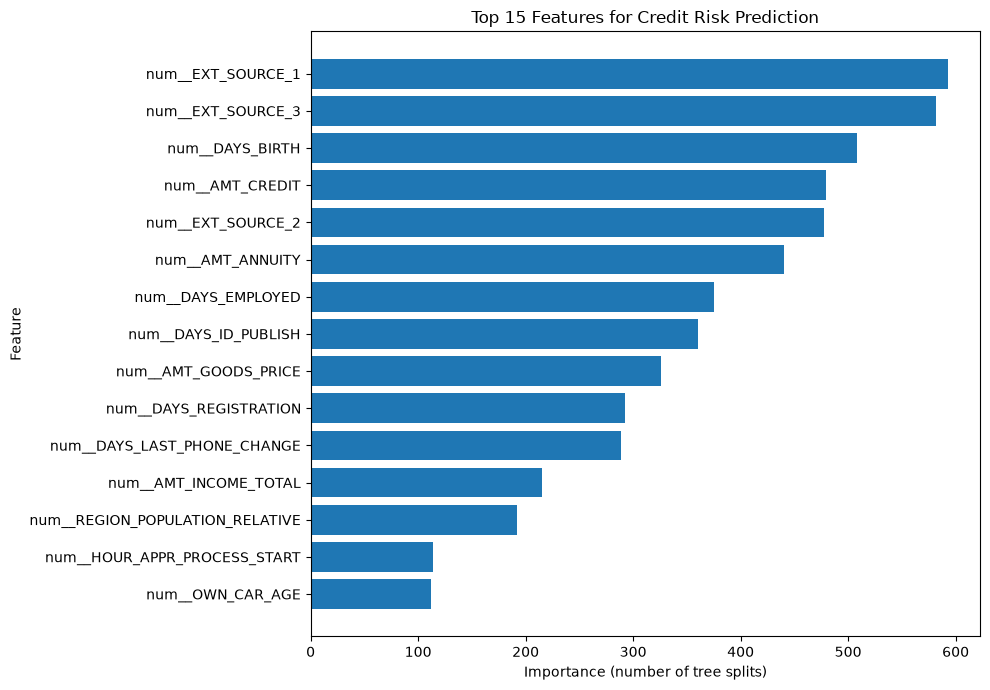

In [115]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance (number of tree splits)")
plt.ylabel("Feature")
plt.title("Top 15 Features for Credit Risk Prediction")
plt.tight_layout()
plt.show()

In [116]:
from sklearn.metrics import classification_report

# Convert predicted probabilities into class predictions
lgbm_pred = lgbm_model.predict(X_test_processed)

# Display evaluation metrics
print(classification_report(
    y_test,
    lgbm_pred,
    target_names=[
        "No payment difficulties",
        "Payment difficulties"
    ]
))

                         precision    recall  f1-score   support

No payment difficulties       0.96      0.72      0.82     56538
   Payment difficulties       0.17      0.67      0.27      4965

               accuracy                           0.71     61503
              macro avg       0.57      0.69      0.55     61503
           weighted avg       0.90      0.71      0.78     61503



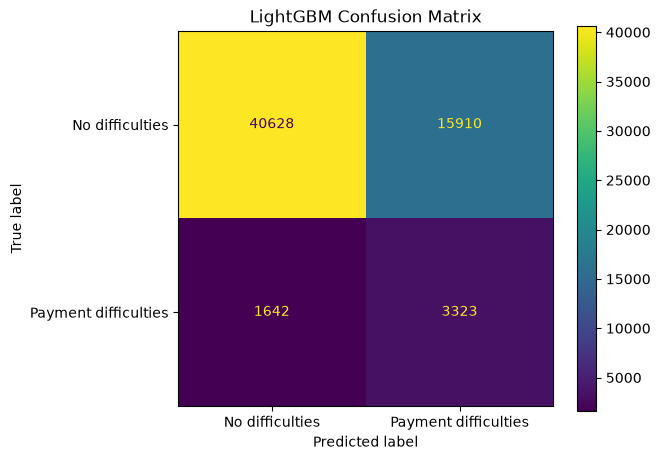

In [117]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lgbm_pred,
    display_labels=[
        "No difficulties",
        "Payment difficulties"
    ],
    values_format="d"
)

plt.title("LightGBM Confusion Matrix")
plt.tight_layout()
plt.show()

In [118]:
from pathlib import Path

# Create the output folder
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison metrics
model_results.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [119]:
feature_importance.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [120]:
import pandas as pd

# Prepare one row per test customer
dashboard_df = pd.DataFrame({
    "actual_target": y_test.to_numpy(),
    "predicted_risk": lgbm_prob
}, index=y_test.index)

# Add gender if available in the original dataset
if "CODE_GENDER" in df.columns:
    dashboard_df["gender"] = df.loc[
        dashboard_df.index, "CODE_GENDER"
    ]

print("Dashboard data prepared!")
print("Number of customers:", len(dashboard_df))
display(dashboard_df.head())

Dashboard data prepared!
Number of customers: 61503


,actual_target,predicted_risk,gender
256571,0,0.415114,M
191493,0,0.283000,F
103497,0,0.817500,M
130646,0,0.401866,F
211898,0,0.576388,F


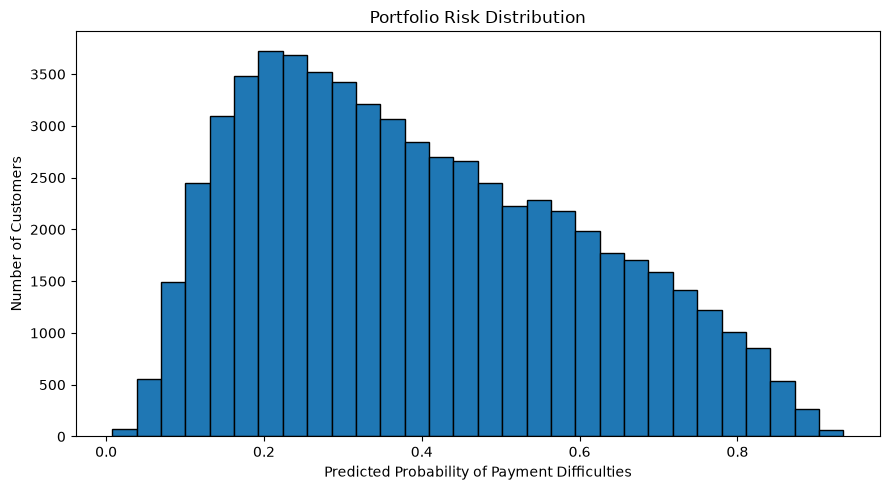

In [121]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    dashboard_df["predicted_risk"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Predicted Probability of Payment Difficulties")
plt.ylabel("Number of Customers")
plt.title("Portfolio Risk Distribution")
plt.tight_layout()
plt.show()

In [122]:
dashboard_df["risk_band"] = pd.cut(
    dashboard_df["predicted_risk"],
    bins=[0, 0.10, 0.25, 1.0],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

risk_summary = (
    dashboard_df["risk_band"]
    .value_counts(sort=False)
    .rename_axis("Risk Band")
    .reset_index(name="Customer Count")
)

risk_summary["Percentage"] = (
    risk_summary["Customer Count"]
    / len(dashboard_df) * 100
).round(2)

display(risk_summary)

,Risk Band,Customer Count,Percentage
0,Low,2103,3.42
1,Medium,15944,25.92
2,High,43456,70.66


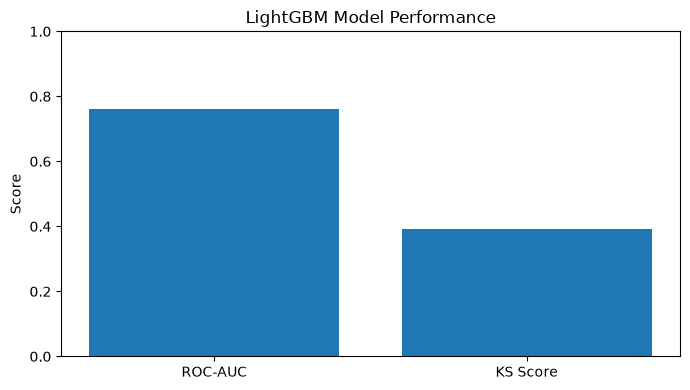

ROC-AUC: 0.7608
KS Score: 39.22


In [123]:
import matplotlib.pyplot as plt

metrics = {
    "ROC-AUC": lgbm_auc,
    "KS Score": lgbm_ks / 100
}

plt.figure(figsize=(7, 4))
plt.bar(metrics.keys(), metrics.values())
plt.title("LightGBM Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

print("ROC-AUC:", round(lgbm_auc, 4))
print("KS Score:", round(lgbm_ks, 2))

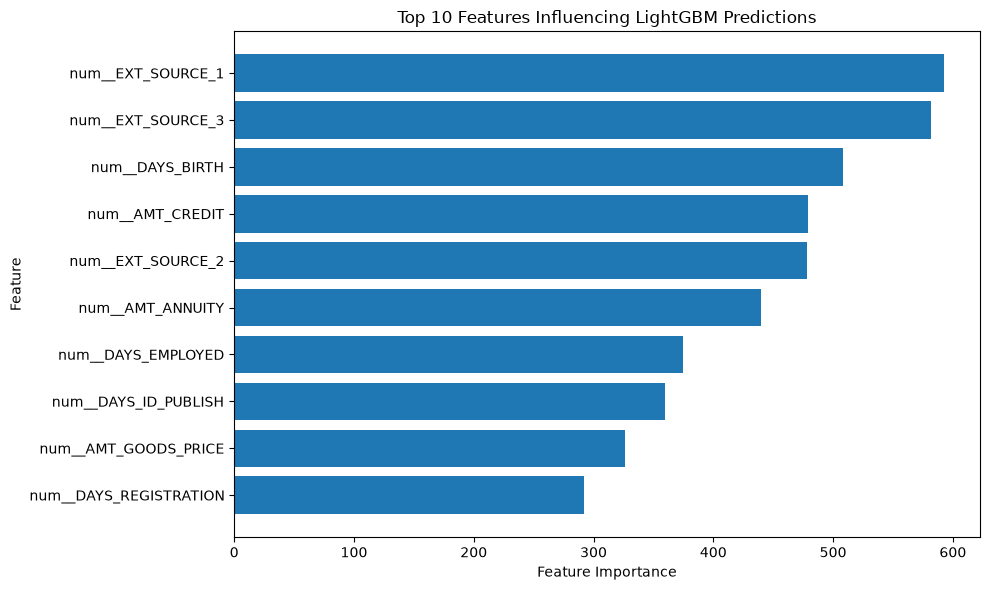

In [124]:
top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing LightGBM Predictions")
plt.tight_layout()
plt.show()

In [125]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

feature_importance.head(15).to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("Top 15 features saved successfully!")

Top 15 features saved successfully!


In [126]:
if "gender" in dashboard_df.columns:
    print("Gender groups found:")
    display(dashboard_df["gender"].value_counts(dropna=False))
else:
    print("Gender column is not available in dashboard data.")

Gender groups found:


gender
F      40561
M      20940
XNA        2
Name: count, dtype: int64

In [127]:
if "gender" in dashboard_df.columns:

    fairness_summary = (
        dashboard_df.groupby("gender", dropna=False)
        .agg(
            Customer_Count=("predicted_risk", "size"),
            Average_Predicted_Risk=("predicted_risk", "mean"),
            Actual_Difficulty_Rate=("actual_target", "mean")
        )
        .reset_index()
    )

    fairness_summary["Average_Predicted_Risk"] = (
        fairness_summary["Average_Predicted_Risk"] * 100
    ).round(2)

    fairness_summary["Actual_Difficulty_Rate"] = (
        fairness_summary["Actual_Difficulty_Rate"] * 100
    ).round(2)

    display(fairness_summary)

else:
    print("No gender column available for comparison.")

,gender,Customer_Count,Average_Predicted_Risk,Actual_Difficulty_Rate
0,F,40561,36.93,6.99
1,M,20940,45.39,10.17
2,XNA,2,48.57,0.00


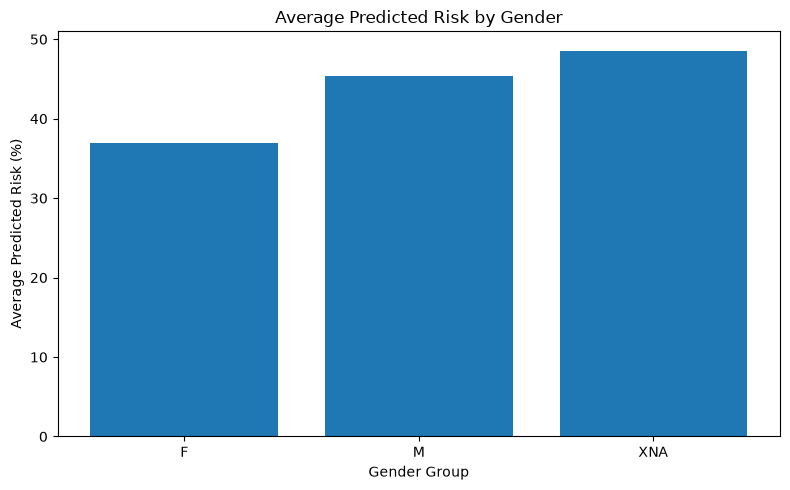

In [128]:
if "gender" in dashboard_df.columns:

    plt.figure(figsize=(8, 5))

    plt.bar(
        fairness_summary["gender"].astype(str),
        fairness_summary["Average_Predicted_Risk"]
    )

    plt.xlabel("Gender Group")
    plt.ylabel("Average Predicted Risk (%)")
    plt.title("Average Predicted Risk by Gender")
    plt.tight_layout()
    plt.show()

In [129]:
if "gender" in dashboard_df.columns:
    fairness_summary.to_csv(
        output_dir / "fairness_comparison.csv",
        index=False
    )

    print("Fairness comparison saved successfully!")

Fairness comparison saved successfully!


In [130]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

fairness_summary.to_csv(
    output_dir / "fairness_comparison.csv",
    index=False
)

print("Fairness comparison saved successfully!")

Fairness comparison saved successfully!


In [131]:
import pandas as pd

dashboard_df = pd.DataFrame({
    "actual_target": y_test.to_numpy(),
    "predicted_risk": lgbm_prob
})

if "CODE_GENDER" in df.columns:
    dashboard_df["gender"] = df.loc[
        y_test.index, "CODE_GENDER"
    ].to_numpy()

display(dashboard_df.head())

,actual_target,predicted_risk,gender
0,0,0.415114,M
1,0,0.283000,F
2,0,0.817500,M
3,0,0.401866,F
4,0,0.576388,F


In [132]:
from pathlib import Path

# Create the outputs folder if it doesn't exist
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save customer-level predictions
dashboard_df.to_csv(
    output_dir / "dashboard_predictions.csv",
    index=False
)

# Save the risk-band summary
risk_summary.to_csv(
    output_dir / "risk_band_summary.csv",
    index=False
)

print("Dashboard data saved successfully!")

Dashboard data saved successfully!


In [133]:
from pathlib import Path

# Start with the original dataset
curated_df = df.drop_duplicates().copy()

# Identify columns with more than 50% missing values
missing_percentage = curated_df.isna().mean() * 100

columns_to_drop = [
    col for col in missing_percentage.index
    if missing_percentage[col] > 50 and col != "TARGET"
]

# Remove those columns
curated_df = curated_df.drop(columns=columns_to_drop)

# Save the curated dataset
curated_dir = Path("../data/curated")
curated_dir.mkdir(parents=True, exist_ok=True)

curated_df.to_csv(
    curated_dir / "application_curated.csv",
    index=False
)

print("Original shape:", df.shape)
print("Curated shape:", curated_df.shape)
print("Saved application_curated.csv")

Original shape: (307511, 122)
Curated shape: (307511, 81)
Saved application_curated.csv


In [134]:

from pathlib import Path
import pandas as pd

# Create the processed folder
processed_dir = Path("../data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Record the preprocessing steps
preprocessing_summary = pd.DataFrame({
    "Step": [
        "Train-test split",
        "Numeric missing values",
        "Categorical missing values",
        "Categorical encoding",
        "Identifier removal"
    ],
    "Method": [
        "80/20 split with stratification",
        "Median imputation",
        "Most-frequent imputation",
        "One-hot encoding",
        "Dropped SK_ID_CURR"
    ],
    "Purpose": [
        "Evaluate on held-out data",
        "Fill missing numeric values",
        "Fill missing categorical values",
        "Convert categories to numeric features",
        "Prevent the identifier being used as a predictor"
    ]
})

# Save the summary
preprocessing_summary.to_csv(
    processed_dir / "preprocessing_summary.csv",
    index=False
)

print("Preprocessing summary saved successfully!")
display(preprocessing_summary)


Preprocessing summary saved successfully!


,Step,Method,Purpose
0,Train-test split,80/20 split with stratification,Evaluate on held-out data
1,Numeric missing values,Median imputation,Fill missing numeric values
2,Categorical missing values,Most-frequent imputation,Fill missing categorical values
3,Categorical encoding,One-hot encoding,Convert categories to numeric features
4,Identifier removal,Dropped SK_ID_CURR,Prevent the identifier being used as a predictor


In [135]:
from pathlib import Path

project_folders = [
    Path("../data/raw"),
    Path("../data/curated"),
    Path("../data/processed"),
    Path("../outputs"),
]

for folder in project_folders:
    print(f"\n{folder}:")
    if folder.exists():
        for file in folder.iterdir():
            if file.is_file():
                print(f"  {file.name} ({file.stat().st_size / 1024:.1f} KB)")
            elif file.is_dir():
                print(f"  {file.name}/")
    else:
        print("  Folder not found")


..\data\raw:
  application_train.csv/

..\data\curated:
  application_curated.csv (118280.3 KB)

..\data\processed:
  preprocessing_summary.csv (0.4 KB)

..\outputs:
  dashboard_predictions.csv (1461.2 KB)
  fairness_comparison.csv (0.1 KB)
  feature_importance.csv (0.4 KB)
  model_comparison.csv (0.1 KB)
  risk_band_summary.csv (0.1 KB)
